# Preparing EuroSAT for Vision Transformer


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader

root = Path.cwd()

if root.name == "analysis":
    root = root.parent

image_dir = root / "Dataset" / "EuroSAT_RGB"
paths = sorted(image_dir.glob("*/*.jpg"))

if not paths:
    raise FileNotFoundError("Open this notebook from the project or analysis folder.")

seed = 42
tiles = pd.DataFrame({"file": [p.relative_to(image_dir).as_posix() for p in paths], "class": [p.parent.name for p in paths]})
classes = sorted(tiles["class"].unique())
label_ids = {name: i for i, name in enumerate(classes)}
tiles["label"] = tiles["class"].map(label_ids)

print(label_ids)

{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


## Read the fixed split

The split was made once with seed 42. Check the saved file before using its train, validation and test groups.

In [ ]:
import hashlib
import json

manifest = json.loads((root / "data/metadata/dataset_manifest.json").read_text())
split_file = root / manifest["split_file"]
if hashlib.sha256(split_file.read_bytes()).hexdigest() != manifest["split_sha256"]:
    raise ValueError("The split file has changed. Check its version before use.")

saved = pd.read_csv(split_file)
assert saved["file"].is_unique and set(saved["file"]) == set(tiles["file"])
assert saved.set_index("file")["label"].sort_index().equals(tiles.set_index("file")["label"].sort_index())
assert saved["class"].map(label_ids).equals(saved["label"])
tiles = saved
parts = ["train", "validation", "test"]
counts = pd.crosstab(tiles["class"], tiles["split"])[parts]
assert counts.sum().to_dict() == manifest["split_counts"]
display(counts)
print("Split totals:", counts.sum().to_dict())

split,train,validation,test
class,,,
AnnualCrop,2400,300,300
Forest,2400,300,300
HerbaceousVegetation,2400,300,300
Highway,2000,250,250
Industrial,2000,250,250
Pasture,1600,200,200
PermanentCrop,2000,250,250
Residential,2400,300,300
River,2000,250,250


Split totals: {'train': 21600, 'validation': 2700, 'test': 2700}


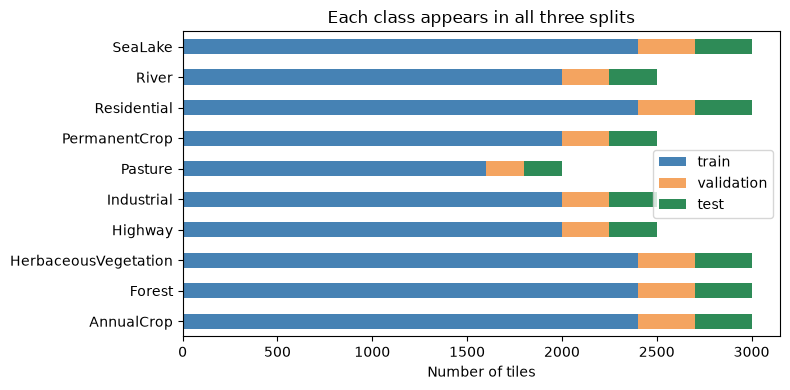

In [ ]:
ax = counts.plot.barh(stacked=True, figsize=(8, 4), color=["steelblue", "sandybrown", "seagreen"])


ax.set(xlabel="Number of tiles", ylabel="", title="Each class appears in all three splits")
ax.legend(title="")
plt.tight_layout()
plt.show()

- The split gives 21,600 images for training and 2,700 images each for validation and testing.
- e.g. Pasture has 200 test images, while Forest has 300.

---

## Scale the pixels and estimate RGB mean and spread

- divide the JPEG values by 255 once. 
- To get the standard deviation across all training pixels, accumulate the sum and the sum of squares for each channel. 
- This includes differences between tiles as well as variation inside each tile.

In [ ]:
def read_rgb(file):
    with Image.open(image_dir / file) as img:

        if img.mode != "RGB" or img.size != (64, 64):
            raise ValueError(f"Unexpected image format for {file}: {img.mode}, {img.size}")

        return np.asarray(img, dtype=np.float32) / 255.0

train_rows = tiles[tiles["split"] == "train"]
channel_sum = np.zeros(3)
square_sum = np.zeros(3)
pixel_count = 0

for file in train_rows["file"]:
    rgb = read_rgb(file).astype(np.float64)
    channel_sum += rgb.sum(axis=(0, 1))
    square_sum += (rgb ** 2).sum(axis=(0, 1))
    pixel_count += rgb.shape[0] * rgb.shape[1]

mean = channel_sum / pixel_count
std = np.sqrt(square_sum / pixel_count - mean ** 2)

assert (std > 0).all()
display(pd.DataFrame({"mean": mean, "std": std}, index=["Red", "Green", "Blue"]).round(4))

,mean,std
Red,0.3447,0.2028
Green,0.3804,0.1368
Blue,0.4079,0.1154


- I keep the native resolution. 
- With 8 × 8 patches, a custom ViT would get an 8 × 8 grid of patches from each tile. For augmentation I use a random quarter-turn and an optional horizontal flip. 

In [ ]:
mean_rgb = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
std_rgb = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

class EuroSATDataset(Dataset):
    def __init__(self, rows, augment=False):
        self.files = rows["file"].tolist()
        self.labels = rows["label"].tolist()
        self.augment = augment

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        image = torch.from_numpy(read_rgb(self.files[index])).permute(2, 0, 1)
        if self.augment:
            turns = torch.randint(4, ()).item()
            image = torch.rot90(image, turns, dims=(1, 2))
            if torch.rand(()).item() < 0.5:
                image = image.flip(dims=(2,))
        image = (image - mean_rgb) / std_rgb
        return image, self.labels[index]

torch.manual_seed(seed)

train_data = EuroSATDataset(train_rows, augment=True)
val_data = EuroSATDataset(tiles[tiles["split"] == "validation"])
test_data = EuroSATDataset(tiles[tiles["split"] == "test"])

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

---
## Check what the model sees

The first plot shows one training tile before augmentation and three draws from the training dataset after a random training transformation.

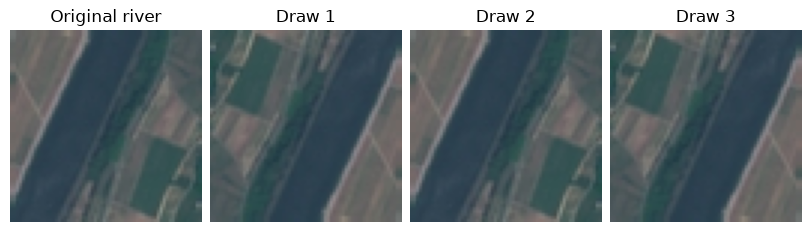

In [ ]:
def for_plot(image):
    return (image * std_rgb + mean_rgb).clamp(0, 1).permute(1, 2, 0).numpy()

index = train_data.labels.index(label_ids["River"])
fig, axes = plt.subplots(1, 4, figsize=(8, 2.5), layout="constrained")
axes[0].imshow(read_rgb(train_data.files[index]))
axes[0].set_title("Original river")

for draw, ax in enumerate(axes[1:], start=1):
    image, _ = train_data[index]
    ax.imshow(for_plot(image))
    ax.set_title(f"Draw {draw}")

for ax in axes:
    ax.axis("off")

plt.show()

train      images [32, 3, 64, 64], labels [32]
validation images [32, 3, 64, 64], labels [32]
test       images [32, 3, 64, 64], labels [32]


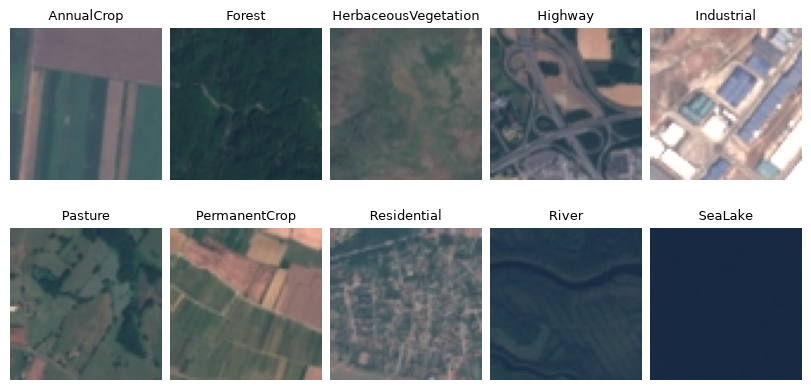

In [ ]:
for split, loader in zip(parts, [train_loader, val_loader, test_loader]):
    images, labels = next(iter(loader))
    
    assert images.shape[1:] == (3, 64, 64) and images.dtype == torch.float32
    assert labels.dtype == torch.long and labels.shape == (len(images),)
    assert labels.min() >= 0 and labels.max() < len(classes)
    assert torch.isfinite(images).all()
    
    print(f"{split:10} images {list(images.shape)}, labels {list(labels.shape)}")

# Reading a validation tile twice should give the same tensor.
assert torch.equal(val_data[0][0], val_data[0][0])
fig, axes = plt.subplots(2, 5, figsize=(8, 4), layout="constrained")

# Take one tile per class
for ax, name in zip(axes.flat, classes):
    index = val_data.labels.index(label_ids[name])
    image, label = val_data[index]
    
    ax.imshow(for_plot(image))
    ax.set_title(classes[label], fontsize=9)
    ax.axis("off")

plt.show()

- Each batch contains 32 RGB images with a size of 64 × 64 pixels.
- The split CSV stores the relative path, class, label number and split so to reuse the same evaluation files.